# Week 7 — Modeling with a differential equation

Companion notebook of the seventh lecture. A **differential equation** states how fast a quantity changes as a function of its current state; with a starting value it determines the whole future. We fit the logistic model to the yeast data, design a drug schedule, learn to solve an equation numerically with `scipy.integrate.solve_ivp`, read phase lines, step through Euler's method and see it fail with a large step, compare it with Runge–Kutta, solve the lake-pollution model, and finally rebuild the **2016 MCM Problem A** bath model of Team 54164 and reproduce its recommended faucet flow.

**How to run**: Anaconda locally (`jupyter lab`), or Colab/Binder from the [course repository](https://github.com/liwt31/MathModel). Run cells in order with `Shift+Enter`.

**Note.** The exercises here and on the slides are **practice for yourself**, and they are **not** the graded assignments. Problem sets are released separately on Blackboard, with due dates.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
try:                                  # optional style file, ships with the course
    plt.style.use("mm.mplstyle")
except OSError:
    pass
# one size for every figure, so the plots fit the notebook column; legends stay small
plt.rcParams.update({"figure.figsize": (6.4, 4.0), "figure.dpi": 100, "legend.fontsize": 9,
                     "legend.framealpha": 0.9, "axes.titlesize": 11})

## 1. Exponential growth and the US census

The Malthusian model $dP/dt = kP$ has the solution $P(t) = P_0 e^{k(t - t_0)}$. The 1970 and 1990 censuses fix $k$; the later censuses test it. The textbook's Table 11.2 also lists the Pearl–Reed logistic curve of 1920.

k from 1970 and 1990: 0.01010 per year
prediction for 2000: 275.1 M (census 281.4 M), for 2300: 5.70 billion


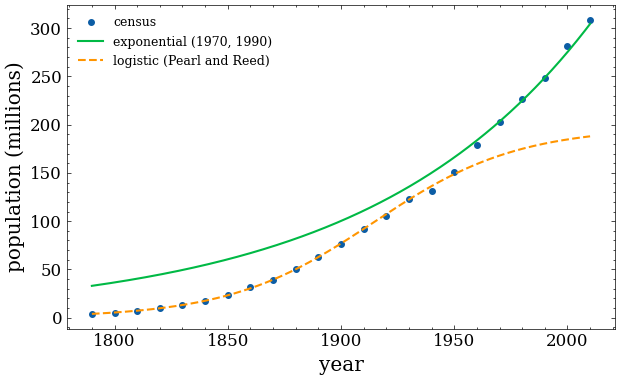

logistic error in 2010: -39.1%


In [2]:
year = np.arange(1790, 2011, 10)
census = np.array([3.929, 5.308, 7.240, 9.638, 12.866, 17.069, 23.192, 31.443, 38.558, 50.156, 62.948, 75.995,
                   91.972, 105.711, 122.755, 131.669, 150.697, 179.323, 203.212, 226.505, 248.710, 281.416, 308.746])  # millions
k = np.log(248.710 / 203.212) / 20
print(f"k from 1970 and 1990: {k:.5f} per year")
malthus = lambda t: 203.212 * np.exp(k * (t - 1970))
print(f"prediction for 2000: {malthus(2000):.1f} M (census 281.4 M), for 2300: {malthus(2300)/1000:.2f} billion")
pearl = lambda t: 197.273522 / (1 + np.exp(-0.03134 * (t - 1914.32)))
t = np.linspace(1790, 2010, 300)
plt.plot(year, census, "o", ms=4, label="census")
plt.plot(t, malthus(t), label="exponential (1970, 1990)")
plt.plot(t, pearl(t), "--", label="logistic (Pearl and Reed)")
plt.xlabel("year"); plt.ylabel("population (millions)"); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()
print("logistic error in 2010:", f"{100 * (pearl(2010) - 308.746) / 308.746:.1f}%")

## 2. The logistic model on the yeast data

The logistic solution satisfies $\ln\frac{P}{M - P} = rM(t - t^*)$, a straight line in $t$. With $M = 665$ a least-squares line through the transformed data gives $rM$ and $t^*$. Week 2 fitted the same data with a difference equation.

In [3]:
yeast = np.array([9.6, 18.3, 29.0, 47.2, 71.1, 119.1, 174.6, 257.3, 350.7, 441.0, 513.3, 559.7, 594.8,
                  629.4, 640.8, 651.1, 655.9, 659.6, 661.8])
hours = np.arange(len(yeast))
for M in [665, 700, 800]:
    z = np.log(yeast / (M - yeast))
    slope, icpt = np.polyfit(hours, z, 1)
    R2 = 1 - np.sum((z - (slope * hours + icpt))**2) / np.sum((z - z.mean())**2)
    print(f"M = {M}: slope rM = {slope:.3f}, intercept = {icpt:.2f}, R^2 = {R2:.4f}, t* = {-icpt/slope:.2f} h")

M = 665: slope rM = 0.531, intercept = -4.16, R^2 = 0.9996, t* = 7.85 h
M = 700: slope rM = 0.419, intercept = -3.71, R^2 = 0.9677, t* = 8.86 h
M = 800: slope rM = 0.346, intercept = -3.59, R^2 = 0.9263, t* = 10.38 h


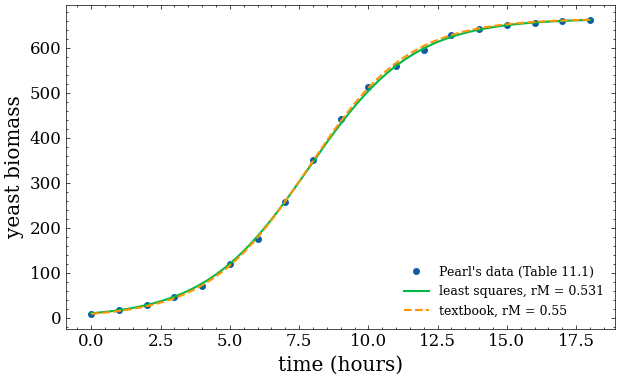

textbook model, percent error by hour: [ -7.4 -16.6 -10.3  -7.1   1.9  -2.3   2.3   0.5  -0.5  -1.   -0.5   1.2
   1.6  -0.1   0.4   0.2   0.3   0.2   0.1]


In [4]:
M = 665
slope, icpt = np.polyfit(hours, np.log(yeast / (M - yeast)), 1)
tstar = -icpt / slope
fit = lambda t: M / (1 + np.exp(-slope * (t - tstar)))
book = lambda t: 665 / (1 + 73.8 * np.exp(-0.55 * t))
tt = np.linspace(0, 18, 200)
plt.plot(hours, yeast, "o", ms=4, label="Pearl's data (Table 11.1)")
plt.plot(tt, fit(tt), label=f"least squares, rM = {slope:.3f}")
plt.plot(tt, book(tt), "--", label="textbook, rM = 0.55")
plt.xlabel("time (hours)"); plt.ylabel("yeast biomass"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()
print("textbook model, percent error by hour:", np.round(100 * (book(hours) - yeast) / yeast, 1))

## 3. Drug dosage: repeated doses

Each dose raises the concentration by $C_0$; between doses $C' = -kC$. The residuals approach $R = C_0/(e^{kT} - 1)$. Setting $R = L$ and $C_0 = H - L$ gives the longest safe interval $T = \frac{1}{k}\ln\frac{H}{L}$, with a loading dose up to $H$ at the start.

R = C0 / (e^kT - 1) = 1.216
schedule: dose H - L = 1.5 mg/ml every T = 69.3 h, first dose H = 2.0


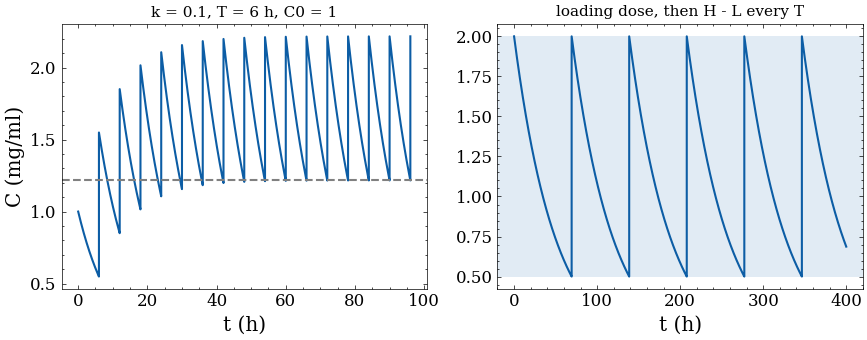

In [5]:
def dose_curve(k, T, C0, first, tmax, n=60):
    t_all, c_all, c = [], [], 0.0
    for j in range(int(tmax // T) + 1):
        t0 = j * T
        c += first if j == 0 else C0
        ts = np.linspace(t0, min(t0 + T, tmax), n)
        t_all.append(ts); c_all.append(c * np.exp(-k * (ts - t0)))
        c = c * np.exp(-k * T)
    return np.concatenate(t_all), np.concatenate(c_all)

k, T, C0 = 0.1, 6.0, 1.0
print(f"R = C0 / (e^kT - 1) = {C0 / (np.exp(k*T) - 1):.3f}")
H, L, k2 = 2.0, 0.5, 0.02                 # Problem 4 of Section 11.2
T2 = np.log(H / L) / k2
print(f"schedule: dose H - L = {H - L} mg/ml every T = {T2:.1f} h, first dose H = {H}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].plot(*dose_curve(k, T, C0, C0, 96)); ax[0].axhline(C0 / (np.exp(k*T) - 1), ls="--", c="gray")
ax[0].set(title="k = 0.1, T = 6 h, C0 = 1", xlabel="t (h)", ylabel="C (mg/ml)")
ax[1].plot(*dose_curve(k2, T2, H - L, H, 400)); ax[1].axhspan(L, H, alpha=0.12)
ax[1].set(title="loading dose, then H - L every T", xlabel="t (h)")
plt.tight_layout(); plt.show()

## 4. Solving an ODE numerically with `solve_ivp`

Most differential equations have no formula for their solution, so we compute the solution numerically. SciPy's `scipy.integrate.solve_ivp` ("solve an initial value problem") does this for any equation written as $dy/dt = f(t, y)$ with a starting value $y(t_0) = y_0$. We learn its parts on a problem whose answer we know, the yeast logistic model $dP/dt = rP(M - P)$ with $r = 0.00082$, $M = 665$, $P(0) = 9.6$.

It needs three arguments.
- **`fun(t, y)`**: a Python function that returns the rate $dy/dt$. Its first argument is always the time `t`, even when the equation does not use it, and `y` arrives as an array (here of length 1).
- **`t_span = (t0, t1)`**: the time interval to solve over.
- **`y0`**: the starting value, as a list or array, `[9.6]`.

It returns an object `sol` with these fields.
- `sol.t`, the times at which the solver stopped, and `sol.y`, the solution there, one row per unknown (`sol.y[0]` is $P$);
- `sol.success` and `sol.message`, to check that it finished.

By default it uses `method="RK45"`, a Runge–Kutta method of order 4–5 (section 6 builds Euler and RK4 by hand). It **chooses its own step size**, taking small steps where the solution changes fast and large ones where it is smooth, so that the estimated error of each step stays below `rtol` × |y| + `atol` (defaults `rtol=1e-3`, `atol=1e-6`).

In [6]:
yeast_rate = lambda t, P: 0.00082 * P * (665 - P)          # dP/dt; t is unused but must be the first argument
sol = solve_ivp(yeast_rate, (0, 18), [9.6])
print(sol.message, "  steps taken:", sol.t.size - 1)
print("times :", np.round(sol.t, 2))
print("P     :", np.round(sol.y[0], 1))
exact = lambda t: 665 * 9.6 / (9.6 + (665 - 9.6) * np.exp(-0.00082 * 665 * t))
print("largest error at those times:", np.abs(sol.y[0] - exact(sol.t)).max().round(3))

The solver successfully reached the end of the integration interval.   steps taken: 9
times : [ 0.    0.11  1.25  3.36  5.91  8.95 12.35 14.87 17.39 18.  ]
P     : [  9.6  10.2  18.7  55.7 179.1 438.1 615.3 651.7 661.6 662.5]
largest error at those times: 0.328


The solver took only a few large steps, so a plot of `sol.t`, `sol.y` would look jagged. Two options give values at the times we want.
- **`t_eval`**: an array of output times; the solver still picks its own steps but reports the solution at these times.
- **`dense_output=True`**: `sol.sol(t)` then evaluates a smooth interpolant at any time `t`.

Tighter tolerances make the answer more accurate at the cost of more steps.

rtol = 1e-03: 200 output points, error 4.6e-01, right-hand side evaluated 62 times
rtol = 1e-06: 200 output points, error 1.3e-03, right-hand side evaluated 170 times
rtol = 1e-09: 200 output points, error 3.2e-06, right-hand side evaluated 602 times


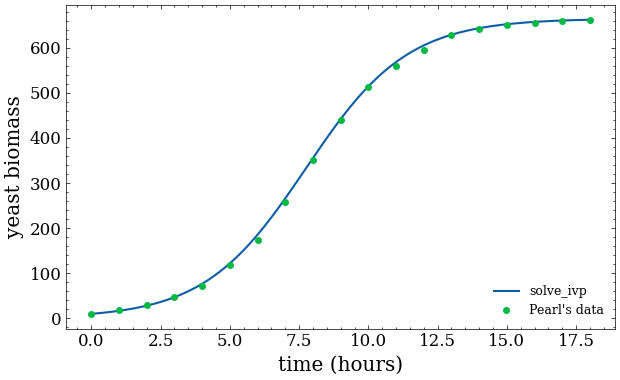

In [7]:
tt = np.linspace(0, 18, 200)
for rtol in [1e-3, 1e-6, 1e-9]:
    s = solve_ivp(yeast_rate, (0, 18), [9.6], t_eval=tt, rtol=rtol, atol=1e-9)
    print(f"rtol = {rtol:.0e}: {s.t.size} output points, error {np.abs(s.y[0] - exact(tt)).max():.1e}, "
          f"right-hand side evaluated {s.nfev} times")
s = solve_ivp(yeast_rate, (0, 18), [9.6], t_eval=tt, rtol=1e-8)
plt.plot(tt, s.y[0], label="solve_ivp"); plt.plot(hours, yeast, "o", ms=4, label="Pearl's data")
plt.xlabel("time (hours)"); plt.ylabel("yeast biomass"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Events.** `events=` stops the solver or records the time when a condition is met. An event is a function `event(t, y)` whose value crosses zero at the moment of interest; setting `event.terminal = True` stops the integration there. When does the yeast reach half its limit, $P = M/2 = 332.5$? The logistic formula gives $t^* = \lnigl((M - P_0)/P_0igr)/(rM) = 7.75$ hours.

In [8]:
half = lambda t, P: P[0] - 332.5                 # zero when P = M/2
half.terminal = True
s = solve_ivp(yeast_rate, (0, 18), [9.6], events=half, rtol=1e-9)
print(f"P reaches 332.5 at t = {s.t_events[0][0]:.4f} h;  formula {np.log((665 - 9.6) / 9.6) / (0.00082 * 665):.4f} h")

P reaches 332.5 at t = 7.7452 h;  formula 7.7452 h


## 5. Phase lines and slope fields

For an autonomous equation $y' = g(y)$, the equilibria are the zeros of $g$, and the sign of $g$ between them gives the arrows of the phase line. Below, `streamplot` draws the slope field as gray curves, and `solve_ivp` from section 4 computes solutions from five starting values. The event stops a solution that runs away above $y = 6$.

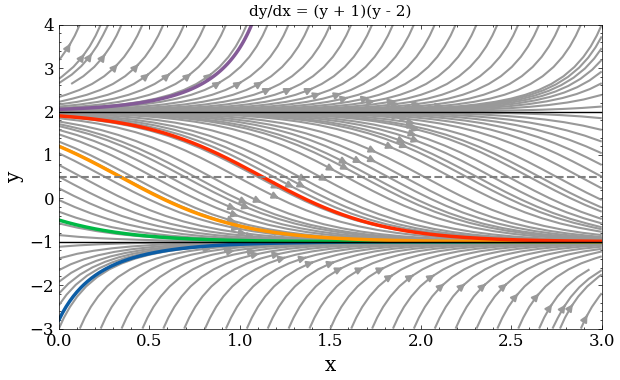

In [9]:
g = lambda y: (y + 1) * (y - 2)
x = np.linspace(0, 3, 30); y = np.linspace(-3, 4, 40)
X, Y = np.meshgrid(x, y)
plt.streamplot(X, Y, np.ones_like(X), g(Y), density=0.9, color="0.6", broken_streamlines=False)
for y0 in [-2.8, -0.5, 1.2, 1.9, 2.05]:
    away = lambda t, y: y[0] - 6; away.terminal = True
    sol = solve_ivp(lambda t, y: g(y[0]), (0, 3), [y0], max_step=0.01, events=away)   # max_step: small steps for a smooth curve
    plt.plot(sol.t, sol.y[0], lw=2.5)
for e in [-1, 2]:
    plt.axhline(e, c="k", lw=1)
plt.axhline(0.5, c="gray", ls="--"); plt.ylim(-3, 4)
plt.xlabel("x"); plt.ylabel("y"); plt.title("dy/dx = (y + 1)(y - 2)"); plt.tight_layout(); plt.show()

### Harvesting

$dP/dt = rP(1 - P/K) - h$ has equilibria where the parabola crosses zero. They exist only for $h \le rK/4$; at $h = rK/4$ they merge, and beyond it every stock collapses.

In [10]:
r, K = 0.5, 100
for h in [6, 12, 12.5, 13]:
    disc = 1 - 4 * h / (r * K)
    eq = [] if disc < 0 else sorted({K/2 * (1 - np.sqrt(disc)), K/2 * (1 + np.sqrt(disc))})
    print(f"h = {h:5.1f}: equilibria {np.round(eq, 2)}")
print("largest sustainable harvest rK/4 =", r * K / 4)

h =   6.0: equilibria [13.94 86.06]
h =  12.0: equilibria [40. 60.]
h =  12.5: equilibria [50.]
h =  13.0: equilibria []
largest sustainable harvest rK/4 = 12.5


## 6. Euler's method

$y_{n+1} = y_n + g(x_n, y_n)\,\Delta x$. Example 1 of Section 11.5 is $y' = 1 + y$, $y(0) = 1$, with exact solution $2e^x - 1$.

In [11]:
def euler(g, x0, y0, dx, n):
    xs, ys = [x0], [y0]
    for _ in range(n):
        ys.append(ys[-1] + g(xs[-1], ys[-1]) * dx); xs.append(xs[-1] + dx)
    return np.array(xs), np.array(ys)

xs, ys = euler(lambda x, y: 1 + y, 0, 1, 0.1, 3)
print("Euler :", np.round(ys, 4)); print("exact :", np.round(2 * np.exp(xs) - 1, 4))

# Table 11.4: dQ/dt = 0.12 Q, Q(0) = 1000, value after 10 years
for dt, name in [(1, "yearly"), (1/12, "monthly"), (1/52, "weekly")]:
    _, Q = euler(lambda t, q: 0.12 * q, 0, 1000, dt, round(10 / dt))
    print(f"{name:8s} steps: Q(10) = {Q[-1]:8.2f}, error {1000*np.exp(1.2) - Q[-1]:7.2f}")

Euler : [1.    1.2   1.42  1.662]
exact : [1.     1.2103 1.4428 1.6997]
yearly   steps: Q(10) =  3105.85, error  214.27
monthly  steps: Q(10) =  3300.39, error   19.73
weekly   steps: Q(10) =  3315.53, error    4.59


### Week 2's yeast model is Euler's method

Euler with a step of one hour on $dP/dt = rP(M - P)$ is $P_{n+1} = P_n + r(M - P_n)P_n$, the Week-2 difference equation with $r = 0.00082$, $M = 665$.

In [12]:
_, Pe = euler(lambda t, p: 0.00082 * p * (665 - p), 0, 9.6, 1.0, 18)
p = [9.6]
for n in range(18):
    p.append(p[-1] + 0.00082 * (665 - p[-1]) * p[-1])
print("identical:", np.allclose(Pe, p), "  P_18 =", round(Pe[-1], 1))

identical: True   P_18 = 663.8


### When Euler goes wrong

For $N' = 0.25N(10 - N)$, $N(0) = 2$ (Project 5 of Section 11.5), the true solution settles at 10. The Euler rule is the logistic map with $\mu = 1 + 2.5h$, so a large step produces oscillations that belong to the method, not to the model.

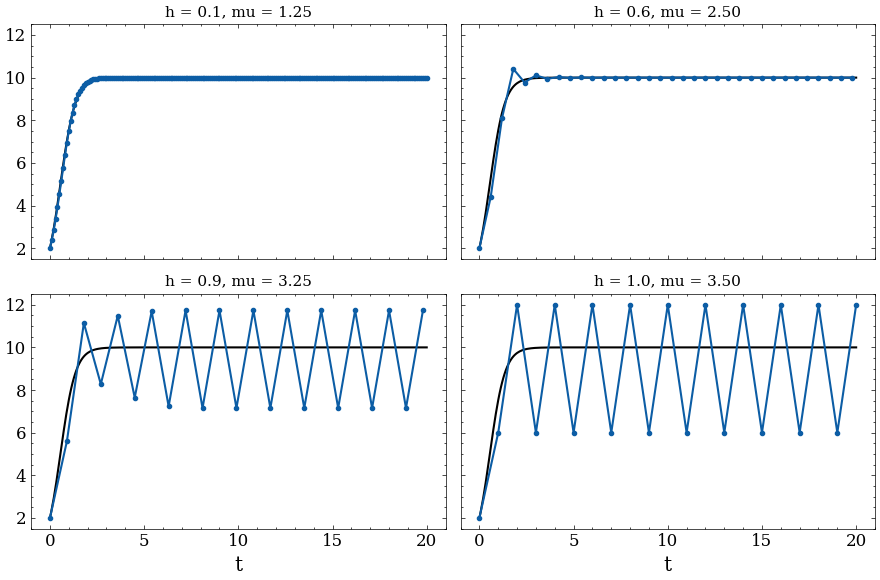

h = 1 from N = 2: [ 2.  6. 12.  6. 12.  6. 12.]


In [13]:
exact = lambda t: 20 / (2 + 8 * np.exp(-2.5 * t))
fig, ax = plt.subplots(2, 2, figsize=(9, 6), sharey=True, sharex=True)
for a, h in zip(ax.flat, [0.1, 0.6, 0.9, 1.0]):
    ts, Ns = euler(lambda t, n: 0.25 * n * (10 - n), 0, 2, h, int(20 / h))
    a.plot(np.linspace(0, 20, 300), exact(np.linspace(0, 20, 300)), c="k")
    a.plot(ts, Ns, "o-", ms=3); a.set_title(f"h = {h}, mu = {1 + 2.5*h:.2f}")
for a in ax[1]: a.set_xlabel("t")
plt.tight_layout(); plt.show()
print("h = 1 from N = 2:", np.round(euler(lambda t, n: 0.25 * n * (10 - n), 0, 2, 1.0, 6)[1], 3))

### Better methods

Improved Euler averages two slopes per step and fourth-order Runge–Kutta averages four. On $y' = 0.25ty$, $y(0) = 2$ (exact $2e^{t^2/8}$), halving the step divides the error at $t = 4$ by about 2, 4 and 16. The last line compares `solve_ivp` (section 4), whose RK45 method is a Runge–Kutta method of this family with an automatic step size.

In [14]:
def step(method, f, t, y, h):
    if method == "Euler":
        return y + h * f(t, y)
    if method == "improved Euler":
        k1 = f(t, y); k2 = f(t + h, y + h * k1); return y + h * (k1 + k2) / 2
    k1 = f(t, y); k2 = f(t + h/2, y + h*k1/2); k3 = f(t + h/2, y + h*k2/2); k4 = f(t + h, y + h*k3)
    return y + h * (k1 + 2*k2 + 2*k3 + k4) / 6

f = lambda t, y: 0.25 * t * y
ex = 2 * np.exp(2)
hs = [1, 0.5, 0.25, 0.125, 0.0625]
for m in ["Euler", "improved Euler", "RK4"]:
    errs = []
    for h in hs:
        t, y = 0.0, 2.0
        for _ in range(round(4 / h)):
            y = step(m, f, t, y, h); t += h
        errs.append(abs(y - ex))
    rate = [errs[i] / errs[i+1] for i in range(len(errs) - 1)]
    print(f"{m:15s} errors {np.array(errs)}  ratio per halving {np.round(rate, 1)}")
sol = solve_ivp(f, [0, 4], [2.0], rtol=1e-8, atol=1e-10)
print(f"solve_ivp: y(4) = {sol.y[0, -1]:.8f}, exact {ex:.8f}, {sol.t.size - 1} steps")

Euler           errors [8.2156122  5.57223978 3.38739095 1.89736459 1.00912693]  ratio per halving [1.5 1.6 1.8 1.9]
improved Euler  errors [1.58792665 0.49455698 0.13824805 0.03650433 0.0093731 ]  ratio per halving [3.2 3.6 3.8 3.9]
RK4             errors [4.45056094e-02 3.81713834e-03 2.77643847e-04 1.86705655e-05
 1.20943401e-06]  ratio per halving [11.7 13.7 14.9 15.4]
solve_ivp: y(4) = 14.77811223, exact 14.77811220, 27 steps


## 7. A polluted lake

$dp/dt = r_{in} c_{in} - r_{out}\, p / V(t)$ with $V(t) = 10^8 + (r_{in} - r_{out})t$ gallons. With $r_{in} = 300$, $r_{out} = 400$ gal/min and $c_{in} = 5$ ppm the integrating factor gives $p(t) = 5\times10^{-4}(10^6 - t) + 3\times10^{-21}(10^6 - t)^4$, so the concentration is $c(t) = 5\times10^{-6} + 3\times10^{-23}(10^6 - t)^3$.

In [15]:
t15 = 1e6 - (1 / 3e-18) ** (1 / 3)      # c(t) = 15 ppm  <=>  3e-18 (1e6 - t)^3 = 1
print(f"closed form: 15 ppm after {t15:,.0f} min = {t15/1440:.0f} days")
rhs = lambda t, p: [300 * 5e-6 - 400 * p[0] / (1e8 - 100 * t)]
hit = lambda t, p: p[0] / (1e8 - 100 * t) - 15e-6
hit.terminal = True
sol = solve_ivp(rhs, [0, 9e5], [3500.0], events=hit, rtol=1e-10, atol=1e-6)
print(f"solve_ivp  : 15 ppm after {sol.t_events[0][0]:,.0f} min")

closed form: 15 ppm after 306,639 min = 213 days
solve_ivp  : 15 ppm after 306,639 min


## 8. Case study: 2016 MCM A, a hot bath (Team 54164)

The team keeps the bath well mixed by swirling, so the tub has one temperature $T(t)$. With the faucet open,

$$\frac{dT}{dt} = -k\,(T - T_a) + r\,(T_h - T), \qquad r = \dot m / m,$$

with room $T_a = 21$ °C, faucet water $T_h = 48$ °C, and the bath starting at 37 °C.

### Fitting the cooling constant

The team measured its own tub (55″ × 23″ × 13″) once a minute for an hour in a 21 °C room. The readings below are read off their figure (minutes 1 to 61). Fitting $T = 21 + A e^{-kt}$ is a line fit of $\ln(T - 21)$; fixing the start at $A = 16$ gives the team's $k = 0.00448$ per minute and $R^2 = 0.973$.

start fixed (A = 16): k = 0.00448 per min, R^2 = 0.9733   (paper: 0.00448, 0.97326)
start free          : k = 0.00406 per min, A = 15.72, R^2 = 0.9878


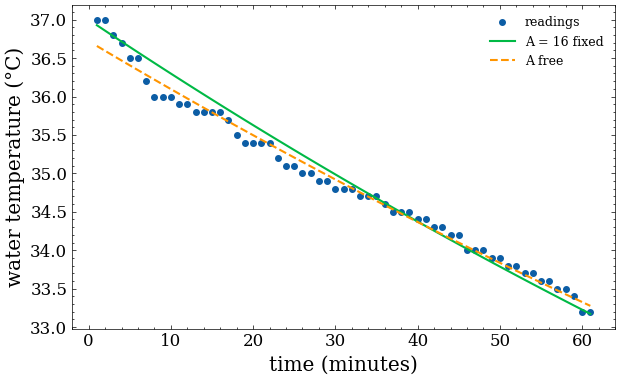

In [16]:
bath = np.array([37.0, 37.0, 36.8, 36.7, 36.5, 36.5, 36.2, 36.0, 36.0, 36.0, 35.9, 35.9, 35.8, 35.8, 35.8, 35.8,
                 35.7, 35.5, 35.4, 35.4, 35.4, 35.4, 35.2, 35.1, 35.1, 35.0, 35.0, 34.9, 34.9, 34.8, 34.8, 34.8,
                 34.7, 34.7, 34.7, 34.6, 34.5, 34.5, 34.5, 34.4, 34.4, 34.3, 34.3, 34.2, 34.2, 34.0, 34.0, 34.0,
                 33.9, 33.9, 33.8, 33.8, 33.7, 33.7, 33.6, 33.6, 33.5, 33.5, 33.4, 33.2, 33.2])
minute = np.arange(1, 62)
z = np.log(bath - 21)
def r2(zhat): return 1 - np.sum((z - zhat)**2) / np.sum((z - z.mean())**2)
k_fixed = -np.sum(minute * (z - np.log(16))) / np.sum(minute**2)          # line through ln 16 at t = 0
k_free, lnA = np.polyfit(minute, z, 1); k_free = -k_free
print(f"start fixed (A = 16): k = {k_fixed:.5f} per min, R^2 = {r2(np.log(16) - k_fixed*minute):.4f}   (paper: 0.00448, 0.97326)")
print(f"start free          : k = {k_free:.5f} per min, A = {np.exp(lnA):.2f}, R^2 = {r2(lnA - k_free*minute):.4f}")
plt.plot(minute, bath, "o", ms=4, label="readings")
plt.plot(minute, 21 + 16 * np.exp(-k_fixed * minute), label="A = 16 fixed")
plt.plot(minute, 21 + np.exp(lnA - k_free * minute), "--", label="A free")
plt.xlabel("time (minutes)"); plt.ylabel("water temperature (°C)"); plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

### From their tub to the standard tub

The team fits $k = 0.3854\,\exp\bigl(-0.1671\,\sqrt[3]{V^2/S^3}\bigr)$ (per second; $V$ in liters, $S$ the open area in m²) through three beaker data sets and their tub, then applies it to the standard 60″ × 30″ × 14″ tub.

In [17]:
IN3_TO_L, IN2_TO_M2 = 0.0163871, 0.00064516
def k_per_min(SA_in2, V_in3):
    V, S = V_in3 * IN3_TO_L, SA_in2 * IN2_TO_M2
    return 0.385387190197681 * np.exp(-0.167081937857622 * np.cbrt(V**2 / S**3)) * 60
print(f"their tub    : k = {k_per_min(1265, 16455):.5f} per min (measured 0.00448)")
print(f"standard tub : k = {k_per_min(1800, 25200):.5f} per min, time constant {1/k_per_min(1800, 25200):.0f} min")

their tub    : k = 0.00450 per min (measured 0.00448)
standard tub : k = 0.00793 per min, time constant 126 min


### The simulation, as the team wrote it

Euler with a step of one minute: cool, switch the faucet on once the bath is 1.4 °C below 37 °C, then heat with $\Delta T = r\,(T_h - T)$. A flow is scored by the **deviance** $\sum (37 - T)^2$ over the minutes with the faucet on, for a 40-minute bath; the flows are scanned from 0.02 to 16 gal/min in steps of 0.01.

standard tub: best flow 1.81 gal/min, deviance 10.179   (paper: 1.81, 10.179)


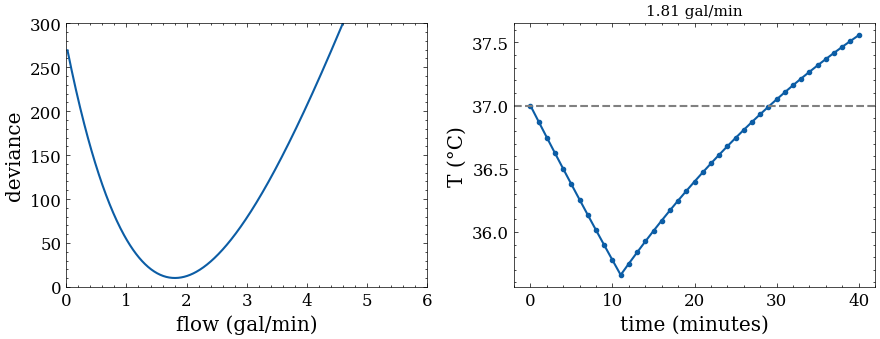

In [18]:
GAL_TO_G, IN3_TO_G = 3785.4118, 16.3870640693
def bath_run(SA, V, flow, minutes=40):
    k, mass = k_per_min(SA, V), V * IN3_TO_G
    T, on, dev, Ts = 37.0, False, 0.0, [37.0]
    for _ in range(minutes):
        T += -k * (T - 21)                          # cooling, one Euler step
        if abs(T - 37) > 1.4 and not on:
            on = True                               # the bather notices and opens the faucet
        if on:
            T += flow * GAL_TO_G * (48 - T) / mass  # mixing with faucet water
            dev += (37 - T)**2
        Ts.append(T)
    return dev, np.array(Ts)

flows = np.arange(2, 1601) / 100
def best_flow(SA, V):
    devs = np.array([bath_run(SA, V, f)[0] for f in flows])
    return flows[devs.argmin()], devs.min(), devs

f_opt, d_opt, devs = best_flow(1800, 25200)
print(f"standard tub: best flow {f_opt:.2f} gal/min, deviance {d_opt:.3f}   (paper: 1.81, 10.179)")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].plot(flows, devs); ax[0].set(xlim=(0, 6), ylim=(0, 300), xlabel="flow (gal/min)", ylabel="deviance")
ax[1].plot(bath_run(1800, 25200, f_opt)[1], "o-", ms=3); ax[1].axhline(37, c="gray", ls="--")
ax[1].set(xlabel="time (minutes)", ylabel="T (°C)", title=f"{f_opt:.2f} gal/min")
plt.tight_layout(); plt.show()

In [19]:
tubs = [("standard", 1800, 25200, 1.81), ("circular", 1680, 25200, 1.61), ("triangular", 1625.81, 25200, 1.95),
        ("square", 1575, 25200, 4.70), ("bubble bath", 1710, 25200, 1.58), ("hemisphere", 1600, 24079.82, 1.58),
        ("oval", 1600, 24000, 1.60), ("quarter circle", 1600, 22400, 1.41), ("trapezoid", 1600, 18200, 2.15)]
print(f"{'tub':15s}{'k/min':>9s}{'best flow':>11s}{'paper':>8s}{'deviance':>10s}")
for name, SA, V, paper in tubs:
    f_b, d_b, _ = best_flow(SA, V)
    print(f"{name:15s}{k_per_min(SA, V):9.4f}{f_b:11.2f}{paper:8.2f}{d_b:10.2f}")

tub                k/min  best flow   paper  deviance
standard          0.0079       1.81    1.81     10.18
circular          0.0045       1.61    1.61      7.85
triangular        0.0034       1.95    1.95      5.16
square            0.0025       4.70    4.70      1.20


bubble bath       0.0052       1.58    1.58      8.75
hemisphere        0.0038       1.58    1.58      6.44
oval              0.0039       1.60    1.60      6.67
quarter circle    0.0058       1.41    1.41      9.00
trapezoid         0.0168       2.15    2.15      9.36


### Reading the bath equation with a phase line

With the faucet always on, $dT/dt = -(k + r)(T - T^*)$ with $T^* = (kT_a + rT_h)/(k + r)$, an asymptotically stable equilibrium with time constant $1/(k + r)$. Setting $T^* = 37$ gives the flow that holds the bath at 37 °C: $k(37 - 21) = r(48 - 37)$.

In [20]:
k = k_per_min(1800, 25200); mass = 25200 * IN3_TO_G
r = 1.81 * GAL_TO_G / mass
Tstar = (k * 21 + r * 48) / (k + r)
print(f"at 1.81 gal/min: r = {r:.4f} per min, T* = {Tstar:.2f} °C, time constant {1/(k + r):.0f} min")
r37 = k * 16 / 11
print(f"flow holding 37 °C: {r37 * mass / GAL_TO_G:.2f} gal/min")

at 1.81 gal/min: r = 0.0166 per min, T* = 39.27 °C, time constant 41 min
flow holding 37 °C: 1.26 gal/min


## Practice exercises

**These are practice for yourself, and they are not the graded assignments.** Problem sets are released separately on Blackboard, with due dates.

1. **Sheep in Tasmania.** The population was 125, 275, 830, 1200, 1750, 1650 in 1814, 1824, …, 1864. Estimate $M$, fit the line of section 2, and plot the logistic curve with the data.
2. **Drug schedule.** With $k = 0.05$ per hour and $H = eL$, compute the interval and plot the concentration with `dose_curve`.
3. **Phase line.** Draw the slope field and solutions of $dy/dx = (y - 1)(y - 2)(y - 3)$ and classify the equilibria.
4. **Euler and the step.** For $N' = 0.25N(10 - N)$, $N(0) = 2$, compute $N(5)$ with Euler for $h = 1$, 0.5, 0.1 and the relative errors; repeat with RK4.
5. **Carbon dioxide in class.** Thirty students each exhale 100 in³ of air with 4% CO₂ twenty times a minute into a 10,000 ft³ room ventilated with 1000 ft³/min of fresh air (0.04% CO₂). Solve with `solve_ivp` for the CO₂ percentage after one hour.
6. **Holding the bath.** Find the flow that holds 37 °C for the circular tub and compare it with the 40-minute optimum. Then rerun `bath_run` with a 90-minute bath: does the best flow change?
